# Challenge #11 — Eco-Architect: vertical profiling for ecosystem biodiversity
## BIOMASS TOM workflow for Lopé, Gabon

### Goal
Evaluate vertical and horizontal forest structure from BIOMASS tomography to support biodiversity-oriented habitat mapping.

### Foundation
- inspect vertical and horizontal TOM reflectivity;
- derive structural descriptors from HH/VV/HV;
- PCA + unsupervised structural-profile clustering;
- local structural heterogeneity.

### Deep dive
- use the available reference land-cover labels (`Savanna`, `Tree cover areas (open)`, `Tree cover areas (Dense)`);
- extract TOM profiles only at labelled points;
- test a 3-class Random Forest;
- test a hierarchical alternative: `Savanna vs Tree cover`, then `Open vs Dense`;
- calculate local structural-diversity proxies (Rao's Q and LCBD-like uniqueness);
- use both repeated stratified CV and spatial CV;
- optionally map the full scene and export GeoTIFFs for QGIS.

**Important:** TOM `z` is a tomographic vertical coordinate, not ground-normalized canopy height. Structural-diversity metrics are habitat-structure proxies, not direct species-diversity measurements.


## STEP 1 — Imports and paths


In [1]:
from pathlib import Path
import time
import warnings

import numpy as np
import pandas as pd
import xarray as xr
import matplotlib.pyplot as plt
import geopandas as gpd


# ============================================================
# INPUT FILES
# ============================================================

tom_path = Path(
    "Examples_and_Data/Workshops/BIOMASS-Coding2026/Lope/TOM/"
    "BIO_TP_TOM_L2A_20251007T050300_20251022T050313_C_G___M___C___T____F001_01_QRDMUH/"
    "measurement/"
    "bio_tp_tom_l2a_20251007t050300_20251022t050313_c_g___m___c___t____f001_geo_tomcubes.nc"
)

points_path = Path(
    "data/Field_Validation_point.geojson"
)

landcover_path = Path(
    "data/LAND_COVER_MAP.geojson"
)


print("TOM file:")
print(tom_path)

print("\nReference points:")
print(points_path)

print("\nLand-cover polygons:")
print(landcover_path)

print("\nExistence check:")
print("TOM     :", tom_path.exists())
print("Points  :", points_path.exists())
print("Polygon :", landcover_path.exists())

TOM file:
Examples_and_Data/Workshops/BIOMASS-Coding2026/Lope/TOM/BIO_TP_TOM_L2A_20251007T050300_20251022T050313_C_G___M___C___T____F001_01_QRDMUH/measurement/bio_tp_tom_l2a_20251007t050300_20251022t050313_c_g___m___c___t____f001_geo_tomcubes.nc

Reference points:
data/Field_Validation_point.geojson

Land-cover polygons:
data/LAND_COVER_MAP.geojson

Existence check:
TOM     : True
Points  : True
Polygon : True


## STEP 2 — Load TOM cube


In [2]:
%pip install h5netcdf h5py


  Using cached h5netcdf-1.8.1-py3-none-any.whl.metadata (15 kB)
Using cached h5netcdf-1.8.1-py3-none-any.whl (62 kB)
Note: you may need to restart the kernel to use updated packages.


In [3]:
# ============================================================
# STEP 2 — LOAD BIOMASS TOM PRODUCT
# ============================================================

import xarray as xr


# ------------------------------------------------------------
# 1. Check available xarray engines
# ------------------------------------------------------------

available_engines = xr.backends.list_engines()

print("Available xarray engines:")
print(available_engines)


# ------------------------------------------------------------
# 2. Choose the best available NetCDF engine
# ------------------------------------------------------------

if "h5netcdf" in available_engines:
    selected_engine = "h5netcdf"

elif "netcdf4" in available_engines:
    selected_engine = "netcdf4"

else:
    raise ImportError(
        "Neither 'h5netcdf' nor 'netcdf4' is available in this kernel.\n"
        "Install one of them, for example with:\n\n"
        "%pip install h5netcdf h5py\n\n"
        "Then restart the kernel and rerun STEP 1 and STEP 2."
    )


print("\nSelected engine:")
print(selected_engine)


# ------------------------------------------------------------
# 3. Open BIOMASS TOM NetCDF
# ------------------------------------------------------------

ds = xr.open_dataset(
    tom_path,
    engine=selected_engine
)


# ------------------------------------------------------------
# 4. Check expected TOM variable
# ------------------------------------------------------------

if "tomographicCubes" not in ds.data_vars:

    raise KeyError(
        "'tomographicCubes' was not found in the dataset.\n"
        f"Available variables: {list(ds.data_vars)}"
    )


# ------------------------------------------------------------
# 5. Extract TOM cube
# ------------------------------------------------------------

cube_raw = ds[
    "tomographicCubes"
]


# ------------------------------------------------------------
# 6. Report
# ------------------------------------------------------------

print("\n" + "=" * 80)
print("BIOMASS TOM PRODUCT LOADED SUCCESSFULLY")
print("=" * 80)

print("\nFile:")
print(tom_path)

print("\nDimensions:")
print(cube_raw.dims)

print("\nShape:")
print(cube_raw.shape)

print("\nData type:")
print(cube_raw.dtype)

Available xarray engines:
{'h5netcdf': <H5netcdfBackendEntrypoint>
  Open netCDF (.nc, .nc4 and .cdf) and most HDF5 files using h5netcdf in Xarray
  Learn more at https://docs.xarray.dev/en/stable/generated/xarray.backends.H5netcdfBackendEntrypoint.html, 'scipy': <ScipyBackendEntrypoint>
  Open netCDF files (.nc, .nc4, .cdf and .gz) using scipy in Xarray
  Learn more at https://docs.xarray.dev/en/stable/generated/xarray.backends.ScipyBackendEntrypoint.html, 'rasterio': <RasterioBackend>, 'store': <StoreBackendEntrypoint>
  Open AbstractDataStore instances in Xarray
  Learn more at https://docs.xarray.dev/en/stable/generated/xarray.backends.StoreBackendEntrypoint.html}

Selected engine:
h5netcdf

BIOMASS TOM PRODUCT LOADED SUCCESSFULLY

File:
Examples_and_Data/Workshops/BIOMASS-Coding2026/Lope/TOM/BIO_TP_TOM_L2A_20251007T050300_20251022T050313_C_G___M___C___T____F001_01_QRDMUH/measurement/bio_tp_tom_l2a_20251007t050300_20251022t050313_c_g___m___c___t____f001_geo_tomcubes.nc

Dimensions:

## STEP 3 — Build correct physical coordinates


In [4]:
lat0 = -0.6662776576023925
lon0 = 10.866410620888747
d_lat = 0.0004166666666666739
d_lon = 0.00041666666666717085

n_lat = cube_raw.sizes["relativeAzimuthTime"]
n_lon = cube_raw.sizes["slantRangeTime"]
n_z   = cube_raw.sizes["tomographicHeight"]
n_pol = cube_raw.sizes["polarizations"]

lat = lat0 + np.arange(n_lat) * d_lat
lon = lon0 + np.arange(n_lon) * d_lon
z = np.arange(-60, 102, 2)
pol = ["HH","VV","HV"]

if len(z) != n_z:
    raise ValueError(f"z mismatch: {len(z)} expected vs {n_z}")
if len(pol) != n_pol:
    raise ValueError(f"polarization mismatch: {len(pol)} expected vs {n_pol}")

cube = (
    cube_raw
    .rename({
        "relativeAzimuthTime":"lat",
        "slantRangeTime":"lon",
        "tomographicHeight":"z",
        "polarizations":"pol",
    })
    .assign_coords(
        lat=("lat",lat),
        lon=("lon",lon),
        z=("z",z),
        pol=("pol",pol),
    )
)

print("Longitude:", float(cube.lon.min()), "->", float(cube.lon.max()))
print("Latitude :", float(cube.lat.min()), "->", float(cube.lat.max()))
print("z        :", float(cube.z.min()), "->", float(cube.z.max()))

if not (10 < float(cube.lon.min()) < 12.5 and -1.5 < float(cube.lat.min()) < 1.5):
    raise ValueError("Geographic sanity check failed.")
print("Geographic sanity check: PASSED")


Longitude: 10.866410620888747 -> 11.690993954223078
Latitude : -0.6662776576023925 -> 0.6924723423976311
z        : -60.0 -> 100.0
Geographic sanity check: PASSED


## STEP 4 — Exploratory ROI


In [5]:
roi = cube.isel(lat=slice(500,900), lon=slice(500,900))
print("ROI shape:", roi.shape)
print("ROI lon:", float(roi.lon.min()), "->", float(roi.lon.max()))
print("ROI lat:", float(roi.lat.min()), "->", float(roi.lat.max()))


ROI shape: (400, 400, 81, 3)
ROI lon: 11.074743954222333 -> 11.240993954222533
ROI lat: -0.4579443242690556 -> -0.29169432426905273


## STEP 5 — Vertical transects and horizontal slices


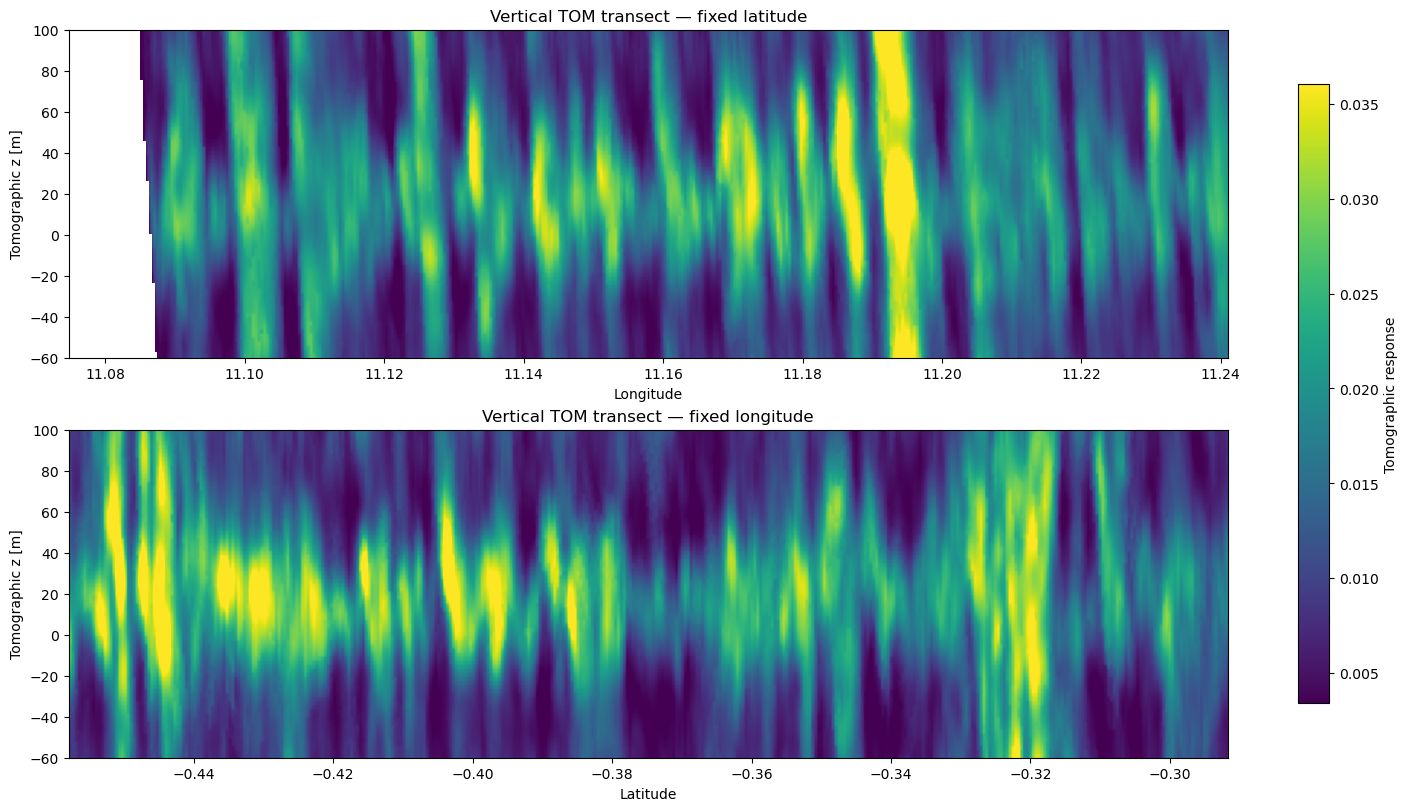

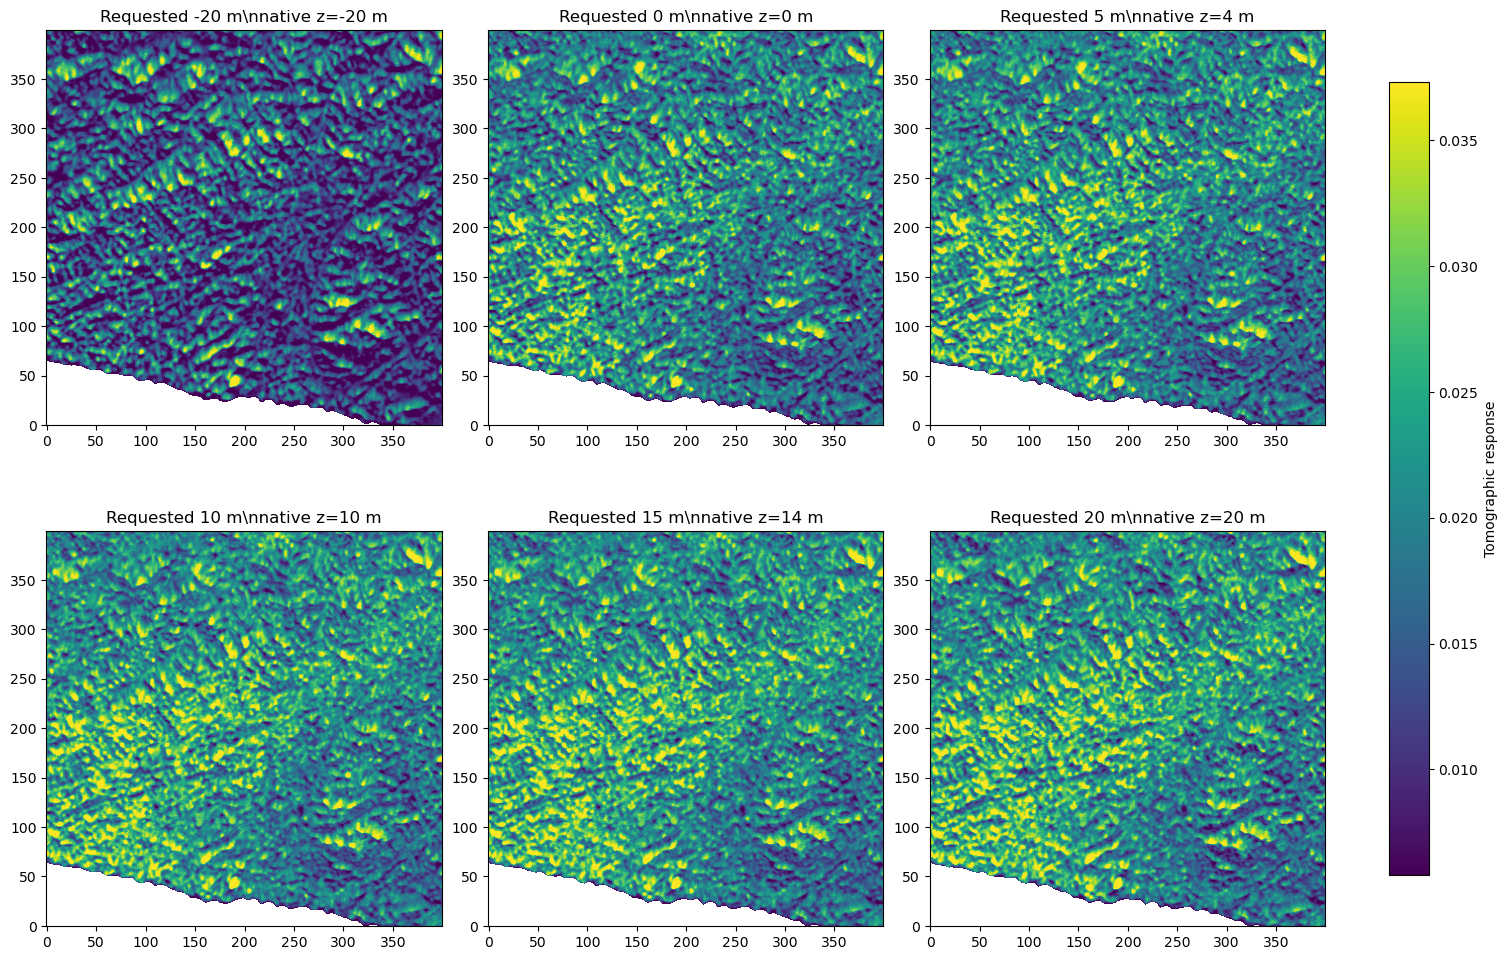

In [6]:
pol_vis = "HV"

ilat_mid = roi.sizes["lat"] // 2
ilon_mid = roi.sizes["lon"] // 2

transect_lon = roi.sel(pol=pol_vis).isel(lat=ilat_mid).transpose("lon","z")
transect_lat = roi.sel(pol=pol_vis).isel(lon=ilon_mid).transpose("lat","z")

vv = np.concatenate([
    transect_lon.values[np.isfinite(transect_lon.values)],
    transect_lat.values[np.isfinite(transect_lat.values)]
])
vmin_v, vmax_v = np.percentile(vv,[2,98])

fig, axes = plt.subplots(2,1,figsize=(14,8),constrained_layout=True)

im = axes[0].imshow(
    transect_lon.values.T, origin="lower", aspect="auto",
    extent=[float(transect_lon.lon.min()),float(transect_lon.lon.max()),
            float(roi.z.min()),float(roi.z.max())],
    vmin=vmin_v,vmax=vmax_v
)
axes[0].set_title("Vertical TOM transect — fixed latitude")
axes[0].set_xlabel("Longitude")
axes[0].set_ylabel("Tomographic z [m]")

axes[1].imshow(
    transect_lat.values.T, origin="lower", aspect="auto",
    extent=[float(transect_lat.lat.min()),float(transect_lat.lat.max()),
            float(roi.z.min()),float(roi.z.max())],
    vmin=vmin_v,vmax=vmax_v
)
axes[1].set_title("Vertical TOM transect — fixed longitude")
axes[1].set_xlabel("Latitude")
axes[1].set_ylabel("Tomographic z [m]")

fig.colorbar(im,ax=axes,label="Tomographic response",shrink=0.85)
plt.show()

requested_heights = [-20,0,5,10,15,20]
z_native = roi.z.values
slices = {}
actual = {}

for h in requested_heights:
    iz = int(np.argmin(np.abs(z_native-h)))
    actual[h] = float(z_native[iz])
    slices[h] = roi.sel(pol=pol_vis).isel(z=iz)

vals = np.concatenate([da.values[np.isfinite(da.values)] for da in slices.values()])
vmin_h,vmax_h = np.percentile(vals,[2,98])

fig,axes = plt.subplots(2,3,figsize=(15,10),constrained_layout=True)
for ax,h in zip(axes.ravel(),requested_heights):
    im = ax.imshow(slices[h].values.T,origin="lower",aspect="equal",vmin=vmin_h,vmax=vmax_h)
    ax.set_title(f"Requested {h} m\\nnative z={actual[h]:.0f} m")
fig.colorbar(im,ax=axes.ravel().tolist(),label="Tomographic response",shrink=0.8)
plt.show()


## STEP 6 — Structural feature processor


In [7]:
# ============================================================
# STEP 6 — TOM STRUCTURAL + AMPLITUDE FEATURE PROCESSOR
# ============================================================

def compute_structural_maps(
    da_pol,
    background_quantile=0.10
):

    arr = (
        da_pol
        .transpose("lat", "lon", "z")
        .values
        .astype(np.float32)
    )

    # --------------------------------------------------------
    # Basic cleaning
    # --------------------------------------------------------

    arr = np.nan_to_num(
        arr,
        nan=0.0
    )

    arr[arr < 0] = 0.0


    # --------------------------------------------------------
    # Original signal validity
    # --------------------------------------------------------

    total0 = arr.sum(
        axis=2
    )

    valid = (
        np.isfinite(total0)
        &
        (total0 > 0)
    )


    # --------------------------------------------------------
    # Background correction
    # --------------------------------------------------------

    baseline = np.quantile(
        arr,
        background_quantile,
        axis=2
    ).astype(np.float32)

    corrected = (
        arr
        -
        baseline[..., None]
    )

    corrected[
        corrected < 0
    ] = 0.0


    # --------------------------------------------------------
    # Absolute TOM signal
    # --------------------------------------------------------

    power = corrected.sum(
        axis=2
    )

    peak = corrected.max(
        axis=2
    )

    valid &= (
        np.isfinite(power)
        &
        (power > 0)
    )


    # Log transform reduces extreme dynamic range
    log_power = np.log1p(
        power
    ).astype(np.float32)

    log_peak = np.log1p(
        peak
    ).astype(np.float32)


    # --------------------------------------------------------
    # Normalized vertical profile
    # --------------------------------------------------------

    p = (
        corrected
        /
        (power[..., None] + 1e-12)
    )


    # --------------------------------------------------------
    # Vertical entropy
    # --------------------------------------------------------

    entropy = (
        -np.sum(
            p
            *
            np.log(
                p + 1e-12
            ),
            axis=2
        )
        /
        np.log(
            arr.shape[2]
        )
    )


    # --------------------------------------------------------
    # Cumulative profile
    # --------------------------------------------------------

    cdf = np.cumsum(
        p,
        axis=2
    )

    zvals = da_pol.z.values


    def qheight(q):

        idx = np.argmax(
            cdf >= q,
            axis=2
        )

        return (
            zvals[idx]
            .astype(np.float32)
        )


    h10 = qheight(0.10)
    h50 = qheight(0.50)
    h90 = qheight(0.90)


    # --------------------------------------------------------
    # Structural descriptors
    # --------------------------------------------------------

    width80 = (
        h90 - h10
    ).astype(np.float32)

    asymmetry = (
        (h90 - h50)
        -
        (h50 - h10)
    ).astype(np.float32)


    # --------------------------------------------------------
    # Invalid pixels
    # --------------------------------------------------------

    for x in [
        width80,
        entropy,
        asymmetry,
        log_power,
        log_peak
    ]:

        x[
            ~valid
        ] = np.nan


    return {

        "width80":
            width80,

        "entropy":
            entropy.astype(np.float32),

        "asymmetry":
            asymmetry,

        "log_power":
            log_power,

        "log_peak":
            log_peak,

        "valid":
            valid
    }

## STEP 7 — Derive ROI features for HH/VV/HV


In [8]:
features_roi = {}
for p in ["HH","VV","HV"]:
    print("Processing",p)
    features_roi[p] = compute_structural_maps(roi.sel(pol=p))
print("Done.")


Processing HH
Processing VV
Processing HV
Done.


## STEP 8 — Polarimetric summary


In [9]:
for metric in ["width80","entropy","asymmetry"]:
    print("\\n",metric.upper())
    for p in ["HH","VV","HV"]:
        x = features_roi[p][metric]
        x = x[np.isfinite(x)]
        print(p, "mean", round(float(np.mean(x)),3),
              "median", round(float(np.median(x)),3),
              "std", round(float(np.std(x)),3))
    print("Correlations")
    for a,b in [("HH","VV"),("HH","HV"),("VV","HV")]:
        x = features_roi[a][metric].ravel()
        y = features_roi[b][metric].ravel()
        m = np.isfinite(x)&np.isfinite(y)
        print(a,b,round(float(np.corrcoef(x[m],y[m])[0,1]),3))


\n WIDTH80
HH mean 77.42 median 78.0 std 16.405
VV mean 77.558 median 78.0 std 16.05
HV mean 77.967 median 78.0 std 16.186
Correlations
HH VV 0.826
HH HV 0.668
VV HV 0.685
\n ENTROPY
HH mean 0.903 median 0.908 std 0.039
VV mean 0.904 median 0.909 std 0.038
HV mean 0.907 median 0.913 std 0.039
Correlations
HH VV 0.909
HH HV 0.832
VV HV 0.843
\n ASYMMETRY
HH mean 6.585 median 6.0 std 17.565
VV mean 5.052 median 4.0 std 17.209
HV mean 1.95 median 2.0 std 16.093
Correlations
HH VV 0.775
HH HV 0.508
VV HV 0.506


## STEP 9 — 9-feature matrix and PCA


In [10]:
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

feature_order=[]
arrs=[]
for p in ["HH","VV","HV"]:
    for metric in ["width80","entropy","asymmetry"]:
        feature_order.append(f"{metric}_{p}")
        arrs.append(features_roi[p][metric].ravel())

X_all = np.column_stack(arrs)
valid_pixels = np.isfinite(X_all).all(axis=1)
X_valid = X_all[valid_pixels]

scaler_roi = StandardScaler()
X_scaled = scaler_roi.fit_transform(X_valid)

pca_roi = PCA(n_components=5,random_state=42)
PC = pca_roi.fit_transform(X_scaled)

for i,v in enumerate(pca_roi.explained_variance_ratio_,1):
    print(f"PC{i}: {100*v:.2f}%")
print("PC1-PC3 cumulative:", round(100*pca_roi.explained_variance_ratio_[:3].sum(),2),"%")

loadings = pd.DataFrame(
    pca_roi.components_.T,
    index=feature_order,
    columns=[f"PC{i}" for i in range(1,6)]
)
print(loadings.round(3))


PC1: 47.76%
PC2: 24.36%
PC3: 10.13%
PC4: 6.36%
PC5: 5.28%
PC1-PC3 cumulative: 82.25 %
                PC1    PC2    PC3    PC4    PC5
width80_HH    0.394  0.026  0.452 -0.216 -0.287
entropy_HH    0.424 -0.083 -0.366 -0.009 -0.285
asymmetry_HH  0.073  0.598 -0.134 -0.325  0.103
width80_VV    0.398  0.001  0.444 -0.198 -0.207
entropy_VV    0.422 -0.083 -0.393 -0.004 -0.234
asymmetry_VV  0.083  0.593 -0.141 -0.292  0.214
width80_HV    0.380 -0.027  0.355  0.248  0.670
entropy_HV    0.413 -0.102 -0.366  0.226  0.356
asymmetry_HV  0.037  0.515  0.116  0.781 -0.329


## STEP 10 — Unsupervised structural clustering


   k  silhouette  davies_bouldin  calinski_harabasz
0  2       0.337           1.106          62823.414
1  3       0.333           0.887          61072.661
2  4       0.327           0.906          70711.758
3  5       0.347           0.885          72161.711


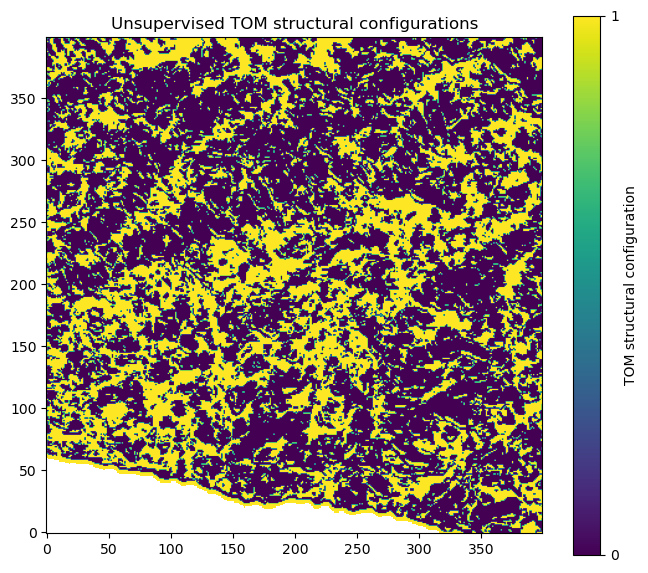

In [11]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score,davies_bouldin_score,calinski_harabasz_score

X_cluster = PC[:,:3]
rows=[]

for k in [2,3,4,5]:
    km=KMeans(n_clusters=k,n_init=20,random_state=42)
    labels=km.fit_predict(X_cluster)
    rows.append({
        "k":k,
        "silhouette":silhouette_score(X_cluster,labels,sample_size=min(10000,len(labels)),random_state=42),
        "davies_bouldin":davies_bouldin_score(X_cluster,labels),
        "calinski_harabasz":calinski_harabasz_score(X_cluster,labels)
    })

cluster_diagnostics=pd.DataFrame(rows)
print(cluster_diagnostics.round(3))

k_final=2
km_final=KMeans(n_clusters=k_final,n_init=30,random_state=42)
cluster_labels=km_final.fit_predict(X_cluster)

flat=np.full(X_all.shape[0],np.nan)
flat[valid_pixels]=cluster_labels
structural_type_map=flat.reshape(roi.sizes["lat"],roi.sizes["lon"])

plt.figure(figsize=(8,7))
im=plt.imshow(structural_type_map.T,origin="lower",aspect="equal",vmin=0,vmax=1)
plt.colorbar(im,ticks=[0,1],label="TOM structural configuration")
plt.title("Unsupervised TOM structural configurations")
plt.show()


## STEP 11 — Local structural heterogeneity


/opt/conda/lib/python3.12/site-packages/numpy/lib/nanfunctions.py:1879: RuntimeWarning: Degrees of freedom <= 0 for slice.
  var = nanvar(a, axis=axis, dtype=dtype, out=out, ddof=ddof,


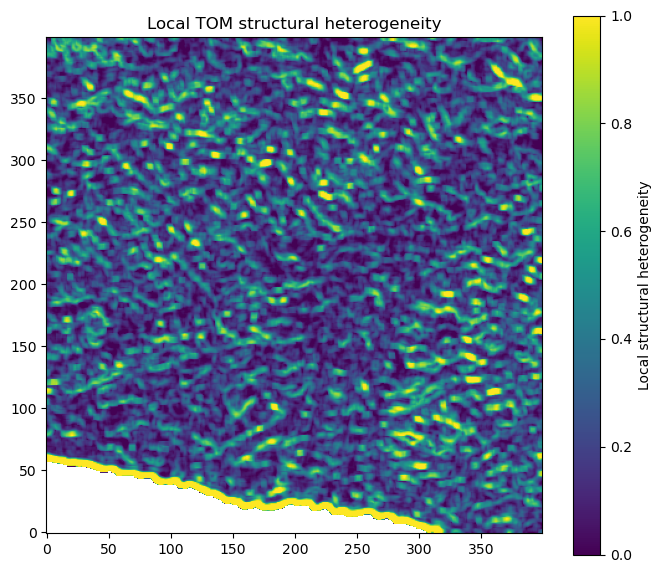

In [12]:
from scipy.ndimage import generic_filter

pc_maps=[]
for i in range(3):
    flat=np.full(X_all.shape[0],np.nan)
    flat[valid_pixels]=PC[:,i]
    pc_maps.append(flat.reshape(roi.sizes["lat"],roi.sizes["lon"]))

window=5
local_sd=[
    generic_filter(pc_map,np.nanstd,size=window,mode="nearest")
    for pc_map in pc_maps
]

structural_heterogeneity=np.sqrt(local_sd[0]**2+local_sd[1]**2+local_sd[2]**2)
f=structural_heterogeneity[np.isfinite(structural_heterogeneity)]
p2,p98=np.percentile(f,[2,98])
structural_heterogeneity_norm=np.clip((structural_heterogeneity-p2)/(p98-p2+1e-12),0,1)

plt.figure(figsize=(8,7))
im=plt.imshow(structural_heterogeneity_norm.T,origin="lower",aspect="equal",vmin=0,vmax=1)
plt.colorbar(im,label="Local structural heterogeneity")
plt.title("Local TOM structural heterogeneity")
plt.show()


## STEP 12 — Load reference land-cover data


In [13]:
if not points_path.exists():
    raise FileNotFoundError(f"{points_path} not found. Upload it beside the notebook or edit STEP 1.")

points=gpd.read_file(points_path)
class_col="Land Cover Class"

print("CRS:",points.crs)
print("N points:",len(points))
print(points[class_col].value_counts())

points_ll=points.to_crs("EPSG:4326")

if landcover_path is not None:
    landcover=gpd.read_file(landcover_path)
    print("Land-cover polygons loaded:",landcover_path)
else:
    landcover=None
    print("No polygon layer found; point validation can still proceed.")


CRS: EPSG:32732
N points: 400
Land Cover Class
Savanna                     100
Tree cover areas (Dense)    100
Tree cover areas (open)     100
Non_vegetetad_area          100
Name: count, dtype: int64
Land-cover polygons loaded: data/LAND_COVER_MAP.geojson


## STEP 13 — Check overlap with TOM footprint


In [14]:
lon_min,lon_max=float(cube.lon.min()),float(cube.lon.max())
lat_min,lat_max=float(cube.lat.min()),float(cube.lat.max())

inside=(
    (points_ll.geometry.x>=lon_min)&(points_ll.geometry.x<=lon_max)&
    (points_ll.geometry.y>=lat_min)&(points_ll.geometry.y<=lat_max)
)

points_tom=points_ll.loc[inside].copy().reset_index(drop=True)

print("Inside TOM:",len(points_tom),"/",len(points_ll))
print(points_tom[class_col].value_counts())

if len(points_tom)==0:
    raise ValueError("No points overlap TOM. Check georeferencing.")


Inside TOM: 398 / 400
Land Cover Class
Tree cover areas (Dense)    100
Non_vegetetad_area          100
Savanna                      99
Tree cover areas (open)      99
Name: count, dtype: int64


## STEP 14 — Extract TOM profiles at reference points


In [15]:
point_lon=points_tom.geometry.x.to_numpy()
point_lat=points_tom.geometry.y.to_numpy()
cube_lon=cube.lon.values
cube_lat=cube.lat.values

lon_idx=np.array([np.abs(cube_lon-x).argmin() for x in point_lon],dtype=int)
lat_idx=np.array([np.abs(cube_lat-y).argmin() for y in point_lat],dtype=int)

pairs=np.column_stack([lat_idx,lon_idx])
unique_pairs,inverse=np.unique(pairs,axis=0,return_inverse=True)

print("Reference points:",len(points_tom))
print("Unique TOM pixels:",len(unique_pairs))

profiles_unique=np.empty(
    (len(unique_pairs),cube.sizes["z"],cube.sizes["pol"]),
    dtype=np.float32
)

t0=time.time()
for i,(ilat,ilon) in enumerate(unique_pairs):
    profiles_unique[i]=(
        cube.isel(lat=int(ilat),lon=int(ilon))
        .transpose("z","pol").values.astype(np.float32)
    )
    if (i+1)%50==0 or (i+1)==len(unique_pairs):
        print(f"{i+1}/{len(unique_pairs)} pixels ({time.time()-t0:.1f}s)")

profiles_all=profiles_unique[inverse]
profiles_at_points={
    "HH":profiles_all[:,:,0],
    "VV":profiles_all[:,:,1],
    "HV":profiles_all[:,:,2],
}

for p in ["HH","VV","HV"]:
    print(p,profiles_at_points[p].shape)


Reference points: 398
Unique TOM pixels: 395
50/395 pixels (30.4s)
100/395 pixels (60.9s)
150/395 pixels (88.0s)
200/395 pixels (115.9s)
250/395 pixels (146.3s)
300/395 pixels (173.2s)
350/395 pixels (203.6s)
395/395 pixels (230.6s)
HH (398, 81)
VV (398, 81)
HV (398, 81)


## STEP 15 — Point-level structural features


In [16]:
# ============================================================
# STEP 15 — EXTRACT TOM FEATURES AT ALL 4 REFERENCE CLASSES
# ============================================================
#
# Final reference classes:
#
# 1. Savanna
# 2. Tree cover areas (open)
# 3. Tree cover areas (Dense)
# 4. Other / non-reference
#
# The original label:
# "Non_vegetetad_area"
# is automatically renamed to:
# "Other / non-reference"
#
# ============================================================

import time
import numpy as np
import pandas as pd
import geopandas as gpd


# ============================================================
# 1. CLASS COLUMN
# ============================================================

class_col = "Land Cover Class"

OTHER_CLASS = "Other / non-reference"


# ------------------------------------------------------------
# Rename the typo in the original dataset
# ------------------------------------------------------------

points[class_col] = (

    points[class_col]
    .replace({

        "Non_vegetetad_area":
            OTHER_CLASS

    })

)


print("=" * 90)
print("REFERENCE CLASSES")
print("=" * 90)

print(
    points[class_col]
    .value_counts()
)


# ============================================================
# 2. CONVERT REFERENCE POINTS TO EPSG:4326
# ============================================================

points_wgs84 = (

    points
    .to_crs(
        "EPSG:4326"
    )
    .copy()

)


print(
    "\nOriginal CRS:",
    points.crs
)

print(
    "Working CRS:",
    points_wgs84.crs
)


# ============================================================
# 3. KEEP ONLY POINTS INSIDE TOM FOOTPRINT
# ============================================================

lon_min = float(
    cube.lon.min()
)

lon_max = float(
    cube.lon.max()
)

lat_min = float(
    cube.lat.min()
)

lat_max = float(
    cube.lat.max()
)


inside = (

    (
        points_wgs84.geometry.x
        >=
        lon_min
    )

    &

    (
        points_wgs84.geometry.x
        <=
        lon_max
    )

    &

    (
        points_wgs84.geometry.y
        >=
        lat_min
    )

    &

    (
        points_wgs84.geometry.y
        <=
        lat_max
    )

)


points_tom = (

    points_wgs84
    .loc[
        inside
    ]
    .copy()
    .reset_index(
        drop=True
    )

)


print("\n" + "=" * 90)
print("POINTS INSIDE TOM FOOTPRINT")
print("=" * 90)

print(
    "Input points:",
    len(points)
)

print(
    "Inside TOM:",
    len(points_tom)
)

print(
    "\nClass distribution:"
)

print(
    points_tom[class_col]
    .value_counts()
)


if len(points_tom) == 0:

    raise ValueError(
        "No reference points overlap the TOM cube."
    )


# ============================================================
# 4. MATCH POINTS TO NEAREST TOM PIXELS
# ============================================================

point_lon = (
    points_tom
    .geometry.x
    .to_numpy()
)

point_lat = (
    points_tom
    .geometry.y
    .to_numpy()
)


cube_lon = (
    cube.lon.values
)

cube_lat = (
    cube.lat.values
)


lon_idx = np.array([

    np.abs(
        cube_lon - x
    ).argmin()

    for x in point_lon

], dtype=int)


lat_idx = np.array([

    np.abs(
        cube_lat - y
    ).argmin()

    for y in point_lat

], dtype=int)


pixel_pairs = np.column_stack([

    lat_idx,
    lon_idx

])


unique_pairs, inverse_idx = np.unique(

    pixel_pairs,

    axis=0,

    return_inverse=True

)


print(
    "\nUnique TOM pixels:",
    len(unique_pairs)
)


# ============================================================
# 5. EXTRACT TOM PROFILES
# ============================================================

n_unique = len(
    unique_pairs
)

n_z = cube.sizes[
    "z"
]

n_pol = cube.sizes[
    "pol"
]


profiles_unique = np.empty(

    (
        n_unique,
        n_z,
        n_pol
    ),

    dtype=np.float32

)


t0 = time.time()


for i, (
    ilat,
    ilon
) in enumerate(
    unique_pairs
):


    profiles_unique[
        i
    ] = (

        cube
        .isel(

            lat=int(
                ilat
            ),

            lon=int(
                ilon
            )

        )
        .transpose(
            "z",
            "pol"
        )
        .values
        .astype(
            np.float32
        )

    )


    if (

        (i + 1) % 25 == 0

        or

        (i + 1) == n_unique

    ):

        print(

            f"{i+1}/{n_unique} "
            f"unique TOM pixels extracted "
            f"({time.time()-t0:.1f} s)"

        )


# Restore one profile for every original reference point

profiles_all = (

    profiles_unique[
        inverse_idx
    ]

)


print(
    "\nProfile array shape:",
    profiles_all.shape
)


# ============================================================
# 6. SEPARATE POLARIZATIONS
# ============================================================

profiles_points = {

    "HH":
        profiles_all[
            :,
            :,
            0
        ],

    "VV":
        profiles_all[
            :,
            :,
            1
        ],

    "HV":
        profiles_all[
            :,
            :,
            2
        ]

}


# ============================================================
# 7. FUNCTION TO COMPUTE STRUCTURAL + AMPLITUDE FEATURES
# ============================================================

def compute_features_from_profiles(
    profiles,
    z_values
):

    """
    Calculate TOM structural and relative signal-strength
    descriptors from vertical profiles.

    Outputs:
        width80
        entropy
        asymmetry
        log_power
        log_peak
        valid

    NOTE:
    z is the TOM vertical coordinate.
    These quantities are NOT interpreted as canopy height
    above ground.
    """

    arr = np.asarray(
        profiles,
        dtype=np.float64
    )

    z_values = np.asarray(
        z_values,
        dtype=np.float64
    )


    # --------------------------------------------------------
    # Basic preprocessing
    # --------------------------------------------------------

    arr = np.nan_to_num(

        arr,

        nan=0.0,
        posinf=0.0,
        neginf=0.0

    )


    # TOM values used as positive reflectivity-like magnitude

    arr = np.clip(
        arr,
        0,
        None
    )


    original_power = (
        arr.sum(
            axis=1
        )
    )


    # --------------------------------------------------------
    # Background correction:
    # subtract 10th percentile from each vertical profile
    # --------------------------------------------------------

    background = np.quantile(

        arr,

        0.10,

        axis=1,

        keepdims=True

    )


    corrected = np.clip(

        arr
        -
        background,

        0,
        None

    )


    # --------------------------------------------------------
    # Signal strength
    # --------------------------------------------------------

    power = corrected.sum(
        axis=1
    )


    peak = corrected.max(
        axis=1
    )


    valid = (

        (original_power > 0)

        &

        (power > 0)

        &

        np.isfinite(
            power
        )

    )


    # --------------------------------------------------------
    # Normalize vertical profile
    # --------------------------------------------------------

    denominator = np.where(

        power > 0,

        power,

        1.0

    )


    p = (

        corrected
        /
        denominator[
            :,
            None
        ]

    )


    cdf = np.cumsum(

        p,

        axis=1

    )


    # --------------------------------------------------------
    # Percentile coordinate helper
    # --------------------------------------------------------

    def percentile_z(
        threshold
    ):

        idx = np.argmax(

            cdf >= threshold,

            axis=1

        )


        out = z_values[
            idx
        ].astype(
            float
        )


        out[
            ~valid
        ] = np.nan


        return out


    h10 = percentile_z(
        0.10
    )

    h50 = percentile_z(
        0.50
    )

    h90 = percentile_z(
        0.90
    )


    # --------------------------------------------------------
    # Structural width
    # --------------------------------------------------------

    width80 = (
        h90
        -
        h10
    )


    # --------------------------------------------------------
    # Asymmetry around profile median
    # --------------------------------------------------------

    asymmetry = (

        (
            h90
            -
            h50
        )

        -

        (
            h50
            -
            h10
        )

    )


    # --------------------------------------------------------
    # Normalized Shannon entropy
    # --------------------------------------------------------

    p_safe = np.where(

        p > 0,

        p,

        1.0

    )


    entropy = (

        -np.sum(

            np.where(

                p > 0,

                p
                *
                np.log(
                    p_safe
                ),

                0.0

            ),

            axis=1

        )

        /

        np.log(
            p.shape[1]
        )

    )


    # --------------------------------------------------------
    # Relative TOM signal-strength descriptors
    # --------------------------------------------------------

    log_power = np.log1p(
        power
    )


    log_peak = np.log1p(
        peak
    )


    # --------------------------------------------------------
    # Invalid profiles -> NaN
    # --------------------------------------------------------

    for variable in [

        width80,
        entropy,
        asymmetry,
        log_power,
        log_peak

    ]:

        variable[
            ~valid
        ] = np.nan


    return {

        "width80":
            width80,

        "entropy":
            entropy,

        "asymmetry":
            asymmetry,

        "log_power":
            log_power,

        "log_peak":
            log_peak,

        "valid":
            valid

    }


# ============================================================
# 8. COMPUTE FEATURES FOR HH / VV / HV
# ============================================================

point_features = {}


for pol_name in [

    "HH",
    "VV",
    "HV"

]:

    print(
        f"\nComputing features: {pol_name}"
    )


    point_features[
        pol_name
    ] = compute_features_from_profiles(

        profiles_points[
            pol_name
        ],

        cube.z.values

    )


# ============================================================
# 9. FEATURE NAMES
# ============================================================

features_9 = [

    "width80_HH",
    "entropy_HH",
    "asymmetry_HH",

    "width80_VV",
    "entropy_VV",
    "asymmetry_VV",

    "width80_HV",
    "entropy_HV",
    "asymmetry_HV"

]


features_15 = [

    "width80_HH",
    "entropy_HH",
    "asymmetry_HH",
    "log_power_HH",
    "log_peak_HH",

    "width80_VV",
    "entropy_VV",
    "asymmetry_VV",
    "log_power_VV",
    "log_peak_VV",

    "width80_HV",
    "entropy_HV",
    "asymmetry_HV",
    "log_power_HV",
    "log_peak_HV"

]


# ============================================================
# 10. BUILD RF DATAFRAME
# ============================================================

rf_data = pd.DataFrame({

    "class":
        points_tom[
            class_col
        ].to_numpy(),

    "lon":
        point_lon,

    "lat":
        point_lat,

    "tom_lat_index":
        lat_idx,

    "tom_lon_index":
        lon_idx

})


for pol_name in [

    "HH",
    "VV",
    "HV"

]:

    for metric in [

        "width80",
        "entropy",
        "asymmetry",
        "log_power",
        "log_peak"

    ]:

        rf_data[

            f"{metric}_{pol_name}"

        ] = (

            point_features[
                pol_name
            ][
                metric
            ]

        )


# ============================================================
# 11. CLEAN DATASET
# ============================================================

rf_clean = (

    rf_data
    .dropna(

        subset=
            features_15
            +
            ["class"]

    )
    .copy()
    .reset_index(
        drop=True
    )

)


# ============================================================
# 12. FINAL CHECK
# ============================================================

print("\n" + "=" * 90)
print("FINAL TOM REFERENCE DATASET")
print("=" * 90)


print(
    "\nReference points inside TOM:",
    len(rf_data)
)


print(
    "Valid samples after TOM feature extraction:",
    len(rf_clean)
)


print(
    "\nValid samples by class:"
)


print(

    rf_clean[
        "class"
    ]
    .value_counts()

)


print(
    "\n15 model features:"
)


for f in features_15:

    print(
        " -",
        f
    )


print(
    "\nMissing values:"
)

print(

    rf_clean[
        features_15
    ]
    .isna()
    .sum()
    .sum()

)


print(
    "\nSTEP 15 completed successfully."
)

REFERENCE CLASSES
Land Cover Class
Savanna                     100
Tree cover areas (Dense)    100
Tree cover areas (open)     100
Other / non-reference       100
Name: count, dtype: int64

Original CRS: EPSG:32732
Working CRS: EPSG:4326

POINTS INSIDE TOM FOOTPRINT
Input points: 400
Inside TOM: 398

Class distribution:
Land Cover Class
Tree cover areas (Dense)    100
Other / non-reference       100
Savanna                      99
Tree cover areas (open)      99
Name: count, dtype: int64

Unique TOM pixels: 395
25/395 unique TOM pixels extracted (13.9 s)
50/395 unique TOM pixels extracted (29.7 s)
75/395 unique TOM pixels extracted (44.8 s)
100/395 unique TOM pixels extracted (59.5 s)
125/395 unique TOM pixels extracted (74.0 s)
150/395 unique TOM pixels extracted (87.0 s)
175/395 unique TOM pixels extracted (100.4 s)
200/395 unique TOM pixels extracted (114.9 s)
225/395 unique TOM pixels extracted (130.1 s)
250/395 unique TOM pixels extracted (145.6 s)
275/395 unique TOM pixels extrac

## STEP 16 — Three-class RF baseline


                    Model  N_features  Accuracy_mean  Balanced_accuracy_mean  \
0         Structural only           9          0.454                   0.446   
1  Structural + amplitude          15          0.641                   0.627   

   Macro_F1_mean  
0          0.441  
1          0.626  

Classification report — 15-feature model
                          precision    recall  f1-score   support

   Other / non-reference       0.86      0.86      0.86        72
                 Savanna       0.64      0.58      0.61        50
Tree cover areas (Dense)       0.54      0.47      0.50        59
 Tree cover areas (open)       0.57      0.67      0.61        64

                accuracy                           0.66       245
               macro avg       0.65      0.65      0.65       245
            weighted avg       0.66      0.66      0.66       245



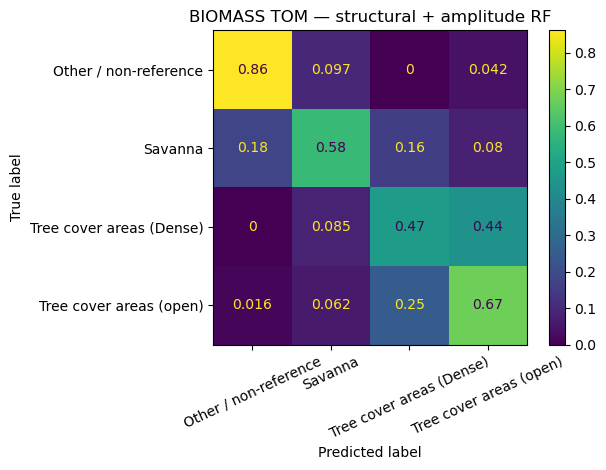

In [17]:
# ============================================================
# STEP 16 — BASELINE vs AMPLITUDE-AWARE RANDOM FOREST
# ============================================================

from sklearn.ensemble import RandomForestClassifier

from sklearn.model_selection import (
    RepeatedStratifiedKFold,
    StratifiedKFold,
    cross_validate,
    cross_val_predict
)

from sklearn.metrics import (
    make_scorer,
    balanced_accuracy_score,
    f1_score,
    classification_report,
    ConfusionMatrixDisplay
)


# ------------------------------------------------------------
# Data
# ------------------------------------------------------------

X9 = rf_clean[
    features_9
]

X15 = rf_clean[
    features_15
]

y3 = rf_clean[
    "class"
]


# ------------------------------------------------------------
# Cross-validation
# ------------------------------------------------------------

cv_repeated = RepeatedStratifiedKFold(
    n_splits=5,
    n_repeats=10,
    random_state=42
)


scoring = {

    "accuracy":
        "accuracy",

    "balanced_accuracy":
        make_scorer(
            balanced_accuracy_score
        ),

    "macro_f1":
        make_scorer(
            f1_score,
            average="macro"
        )
}


def make_rf():

    return RandomForestClassifier(
        n_estimators=600,
        max_features="sqrt",
        min_samples_leaf=2,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    )


# ------------------------------------------------------------
# Baseline
# ------------------------------------------------------------

scores9 = cross_validate(
    make_rf(),
    X9,
    y3,
    cv=cv_repeated,
    scoring=scoring,
    n_jobs=-1
)


# ------------------------------------------------------------
# Amplitude-aware
# ------------------------------------------------------------

scores15 = cross_validate(
    make_rf(),
    X15,
    y3,
    cv=cv_repeated,
    scoring=scoring,
    n_jobs=-1
)


comparison_amplitude = pd.DataFrame({

    "Model": [
        "Structural only",
        "Structural + amplitude"
    ],

    "N_features": [
        9,
        15
    ],

    "Accuracy_mean": [

        scores9[
            "test_accuracy"
        ].mean(),

        scores15[
            "test_accuracy"
        ].mean()
    ],

    "Balanced_accuracy_mean": [

        scores9[
            "test_balanced_accuracy"
        ].mean(),

        scores15[
            "test_balanced_accuracy"
        ].mean()
    ],

    "Macro_F1_mean": [

        scores9[
            "test_macro_f1"
        ].mean(),

        scores15[
            "test_macro_f1"
        ].mean()
    ]

})


print(
    comparison_amplitude.round(3)
)


# ------------------------------------------------------------
# Confusion matrix for 15-feature model
# ------------------------------------------------------------

cv_cm = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)


rf_15_model = make_rf()


pred_15 = cross_val_predict(
    rf_15_model,
    X15,
    y3,
    cv=cv_cm,
    n_jobs=-1
)


print(
    "\nClassification report — 15-feature model"
)

print(
    classification_report(
        y3,
        pred_15
    )
)


ConfusionMatrixDisplay.from_predictions(
    y3,
    pred_15,
    normalize="true",
    xticks_rotation=25
)

plt.title(
    "BIOMASS TOM — structural + amplitude RF"
)

plt.tight_layout()
plt.show()

## STEP 17 — Savanna vs Tree cover


SAVANNA vs TREE COVER

Samples:
binary_class
Tree cover    123
Savanna        50
Name: count, dtype: int64

Balanced accuracy: 0.824 +/- 0.062
Macro F1: 0.834 +/- 0.059

Classification report:
              precision    recall  f1-score   support

     Savanna       0.82      0.72      0.77        50
  Tree cover       0.89      0.93      0.91       123

    accuracy                           0.87       173
   macro avg       0.85      0.83      0.84       173
weighted avg       0.87      0.87      0.87       173



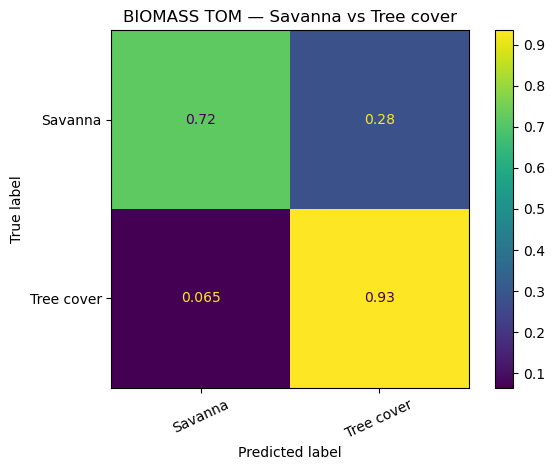

In [21]:
# ============================================================
# STEP 17 — SAVANNA vs TREE COVER
# Correct version for the new 4-class dataset
# ============================================================

from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import (
    RepeatedStratifiedKFold,
    StratifiedKFold,
    cross_validate,
    cross_val_predict
)
from sklearn.metrics import (
    balanced_accuracy_score,
    f1_score,
    make_scorer,
    classification_report,
    ConfusionMatrixDisplay
)

# ------------------------------------------------------------
# Keep ONLY vegetation classes
# Exclude Other / non-reference
# ------------------------------------------------------------

vegetation_classes = [
    "Savanna",
    "Tree cover areas (Dense)",
    "Tree cover areas (open)"
]

rf_veg = (
    rf_clean[
        rf_clean["class"].isin(vegetation_classes)
    ]
    .copy()
    .reset_index(drop=True)
)

# ------------------------------------------------------------
# Binary target
# ------------------------------------------------------------

rf_veg["binary_class"] = np.where(
    rf_veg["class"] == "Savanna",
    "Savanna",
    "Tree cover"
)

X_binary = rf_veg[features_15]
y_binary = rf_veg["binary_class"]

print("=" * 80)
print("SAVANNA vs TREE COVER")
print("=" * 80)

print("\nSamples:")
print(y_binary.value_counts())

# ------------------------------------------------------------
# RF
# ------------------------------------------------------------

rf_binary = RandomForestClassifier(
    n_estimators=700,
    max_features="sqrt",
    min_samples_leaf=2,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1
)

cv_rep = RepeatedStratifiedKFold(
    n_splits=5,
    n_repeats=10,
    random_state=42
)

scoring = {
    "balanced_accuracy":
        make_scorer(balanced_accuracy_score),

    "macro_f1":
        make_scorer(
            f1_score,
            average="macro"
        )
}

scores = cross_validate(
    rf_binary,
    X_binary,
    y_binary,
    cv=cv_rep,
    scoring=scoring,
    n_jobs=-1
)

print(
    "\nBalanced accuracy:",
    round(
        scores["test_balanced_accuracy"].mean(),
        3
    ),
    "+/-",
    round(
        scores["test_balanced_accuracy"].std(),
        3
    )
)

print(
    "Macro F1:",
    round(
        scores["test_macro_f1"].mean(),
        3
    ),
    "+/-",
    round(
        scores["test_macro_f1"].std(),
        3
    )
)

# ------------------------------------------------------------
# Out-of-fold predictions
# ------------------------------------------------------------

cv_cm = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

pred_binary = cross_val_predict(
    rf_binary,
    X_binary,
    y_binary,
    cv=cv_cm,
    n_jobs=-1
)

print("\nClassification report:")
print(
    classification_report(
        y_binary,
        pred_binary
    )
)

ConfusionMatrixDisplay.from_predictions(
    y_binary,
    pred_binary,
    normalize="true",
    xticks_rotation=25
)

plt.title(
    "BIOMASS TOM — Savanna vs Tree cover"
)

plt.tight_layout()
plt.show()

## STEP 18 — Open vs Dense tree cover


OPEN vs DENSE TREE COVER
Balanced accuracy: 0.552 +/- 0.094
Macro F1: 0.548 +/- 0.096
                          precision    recall  f1-score   support

Tree cover areas (Dense)       0.50      0.49      0.50        59
 Tree cover areas (open)       0.54      0.55      0.54        64

                accuracy                           0.52       123
               macro avg       0.52      0.52      0.52       123
            weighted avg       0.52      0.52      0.52       123



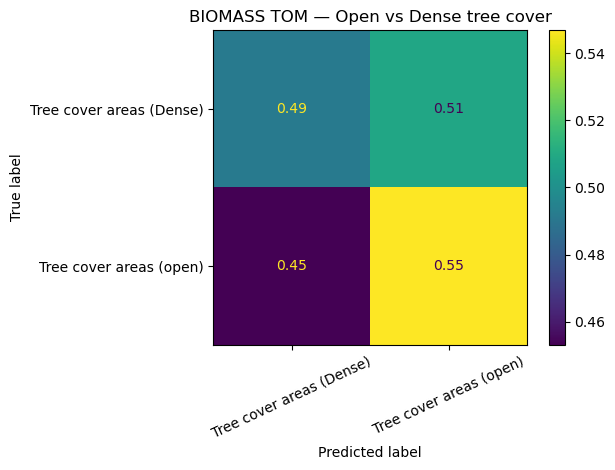

In [19]:
# ============================================================
# STEP 18 — OPEN vs DENSE TREE COVER
# ============================================================

tree_data = rf_clean[

    rf_clean[
        "class"
    ].isin([

        "Tree cover areas (Dense)",

        "Tree cover areas (open)"
    ])

].copy()


X_tree = tree_data[
    features_15
]

y_tree = tree_data[
    "class"
]


rf_tree = RandomForestClassifier(
    n_estimators=700,
    max_features="sqrt",
    min_samples_leaf=2,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1
)


tree_scores = cross_validate(
    rf_tree,
    X_tree,
    y_tree,
    cv=cv_repeated,
    scoring=scoring,
    n_jobs=-1
)


print("=" * 80)
print("OPEN vs DENSE TREE COVER")
print("=" * 80)

print(
    "Balanced accuracy:",
    round(
        tree_scores[
            "test_balanced_accuracy"
        ].mean(),
        3
    ),
    "+/-",
    round(
        tree_scores[
            "test_balanced_accuracy"
        ].std(),
        3
    )
)

print(
    "Macro F1:",
    round(
        tree_scores[
            "test_macro_f1"
        ].mean(),
        3
    ),
    "+/-",
    round(
        tree_scores[
            "test_macro_f1"
        ].std(),
        3
    )
)


pred_tree = cross_val_predict(
    rf_tree,
    X_tree,
    y_tree,
    cv=cv_cm,
    n_jobs=-1
)


print(
    classification_report(
        y_tree,
        pred_tree
    )
)


ConfusionMatrixDisplay.from_predictions(
    y_tree,
    pred_tree,
    normalize="true",
    xticks_rotation=25
)

plt.title(
    "BIOMASS TOM — Open vs Dense tree cover"
)

plt.tight_layout()
plt.show()

## STEP 19 — Local Rao's Q at labelled points


In [20]:
# ============================================================
# STEP 19 — LOCAL RAO'S Q AT LABELLED POINTS
# ============================================================

from scipy.spatial.distance import pdist, squareform


def rao_q_equal_weights(X):

    X = np.asarray(
        X,
        dtype=float
    )

    X = X[
        np.isfinite(X).all(axis=1)
    ]

    if len(X) < 2:
        return np.nan

    D = squareform(
        pdist(
            X,
            metric="euclidean"
        )
    )

    n = len(X)

    p = np.ones(n) / n

    return float(
        np.sum(
            D
            *
            np.outer(
                p,
                p
            )
        )
    )


# ------------------------------------------------------------
# Window size
# ------------------------------------------------------------

rao_window = 5

half = (
    rao_window
    //
    2
)


# ------------------------------------------------------------
# Output array
# ------------------------------------------------------------

rao_q_points = np.full(
    len(points_tom),
    np.nan,
    dtype=float
)


t0 = time.time()


# ------------------------------------------------------------
# Process each reference point
# ------------------------------------------------------------

for i in range(
    len(points_tom)
):

    ilat = int(
        lat_idx[i]
    )

    ilon = int(
        lon_idx[i]
    )


    lat0_patch = max(
        0,
        ilat - half
    )

    lat1_patch = min(
        cube.sizes["lat"],
        ilat + half + 1
    )


    lon0_patch = max(
        0,
        ilon - half
    )

    lon1_patch = min(
        cube.sizes["lon"],
        ilon + half + 1
    )


    # --------------------------------------------------------
    # Extract local TOM patch
    # --------------------------------------------------------

    patch = cube.isel(

        lat=slice(
            lat0_patch,
            lat1_patch
        ),

        lon=slice(
            lon0_patch,
            lon1_patch
        )
    )


    # --------------------------------------------------------
    # Compute structural maps
    # --------------------------------------------------------

    pf = {}

    for pol_name in [
        "HH",
        "VV",
        "HV"
    ]:

        pf[
            pol_name
        ] = compute_structural_maps(

            patch.sel(
                pol=pol_name
            )
        )


    # --------------------------------------------------------
    # Build original 9-dimensional structural space
    # --------------------------------------------------------

    X_patch = np.column_stack([

        pf["HH"]["width80"].ravel(),
        pf["HH"]["entropy"].ravel(),
        pf["HH"]["asymmetry"].ravel(),

        pf["VV"]["width80"].ravel(),
        pf["VV"]["entropy"].ravel(),
        pf["VV"]["asymmetry"].ravel(),

        pf["HV"]["width80"].ravel(),
        pf["HV"]["entropy"].ravel(),
        pf["HV"]["asymmetry"].ravel()

    ])


    valid_patch = np.isfinite(
        X_patch
    ).all(
        axis=1
    )


    X_patch = (
        X_patch[
            valid_patch
        ]
    )


    if len(
        X_patch
    ) >= 3:

        # ----------------------------------------------------
        # Use same PCA structural space from Foundation
        # ----------------------------------------------------

        X_patch_scaled = (
            scaler_roi
            .transform(
                X_patch
            )
        )


        PC_patch = (
            pca_roi
            .transform(
                X_patch_scaled
            )[
                :,
                :3
            ]
        )


        # ----------------------------------------------------
        # Rao's Q
        # ----------------------------------------------------

        rao_q_points[
            i
        ] = rao_q_equal_weights(
            PC_patch
        )


    if (
        (i + 1) % 25 == 0
        or
        (i + 1) == len(points_tom)
    ):

        print(
            f"{i+1}/{len(points_tom)} "
            f"points processed "
            f"({time.time()-t0:.1f} s)"
        )


# ------------------------------------------------------------
# IMPORTANT:
# add Rao Q to rf_data
# ------------------------------------------------------------

rf_data[
    "rao_q_local"
] = rao_q_points


print(
    "\nRao Q added to rf_data."
)

print(
    rf_data[
        "rao_q_local"
    ].describe()
)


print(
    "\nMedian Rao Q by class:"
)

print(
    rf_data
    .groupby(
        "class"
    )[
        "rao_q_local"
    ]
    .median()
    .round(3)
)

25/398 points processed (14.7 s)
50/398 points processed (29.9 s)
75/398 points processed (46.0 s)
100/398 points processed (61.0 s)
125/398 points processed (75.4 s)
150/398 points processed (91.5 s)
175/398 points processed (105.6 s)
200/398 points processed (119.1 s)
225/398 points processed (135.8 s)
250/398 points processed (151.5 s)
275/398 points processed (164.6 s)
300/398 points processed (179.0 s)
325/398 points processed (192.8 s)
350/398 points processed (207.1 s)
375/398 points processed (222.9 s)
398/398 points processed (236.7 s)

Rao Q added to rf_data.
count    246.000000
mean       2.625490
std        1.514561
min        0.560294
25%        1.436487
50%        2.292828
75%        3.360541
max        9.387605
Name: rao_q_local, dtype: float64

Median Rao Q by class:
class
Other / non-reference       3.747
Savanna                     2.694
Tree cover areas (Dense)    1.639
Tree cover areas (open)     1.394
Name: rao_q_local, dtype: float64


## STEP 20 — Baseline vs Baseline + Rao Q


In [22]:
features_rao=features_9+["rao_q_local"]
rf_rao=rf_data.dropna(subset=features_rao+["class"]).copy()

X_base=rf_rao[features_9]
X_rao=rf_rao[features_rao]
y_rao=rf_rao["class"]

rf_base=RandomForestClassifier(
    n_estimators=600,max_features="sqrt",min_samples_leaf=2,
    class_weight="balanced",random_state=42,n_jobs=-1
)

rf_with_rao=RandomForestClassifier(
    n_estimators=600,max_features="sqrt",min_samples_leaf=2,
    class_weight="balanced",random_state=42,n_jobs=-1
)

s0=cross_validate(rf_base,X_base,y_rao,cv=cv_repeated,scoring=scoring,n_jobs=-1)
s1=cross_validate(rf_with_rao,X_rao,y_rao,cv=cv_repeated,scoring=scoring,n_jobs=-1)

comparison=pd.DataFrame({
    "model":["Baseline TOM","Baseline + Rao Q"],
    "balanced_accuracy_mean":[s0["test_balanced_accuracy"].mean(),s1["test_balanced_accuracy"].mean()],
    "balanced_accuracy_sd":[s0["test_balanced_accuracy"].std(),s1["test_balanced_accuracy"].std()],
    "macro_f1_mean":[s0["test_macro_f1"].mean(),s1["test_macro_f1"].mean()],
    "macro_f1_sd":[s0["test_macro_f1"].std(),s1["test_macro_f1"].std()],
})
print(comparison.round(3))


              model  balanced_accuracy_mean  balanced_accuracy_sd  \
0      Baseline TOM                   0.446                 0.065   
1  Baseline + Rao Q                   0.509                 0.061   

   macro_f1_mean  macro_f1_sd  
0          0.441        0.068  
1          0.505        0.063  


## STEP 21 — LCBD-like structural uniqueness


class
Other / non-reference       0.003807
Savanna                     0.003485
Tree cover areas (Dense)    0.001292
Tree cover areas (open)     0.001525
Name: structural_lcbd, dtype: float64


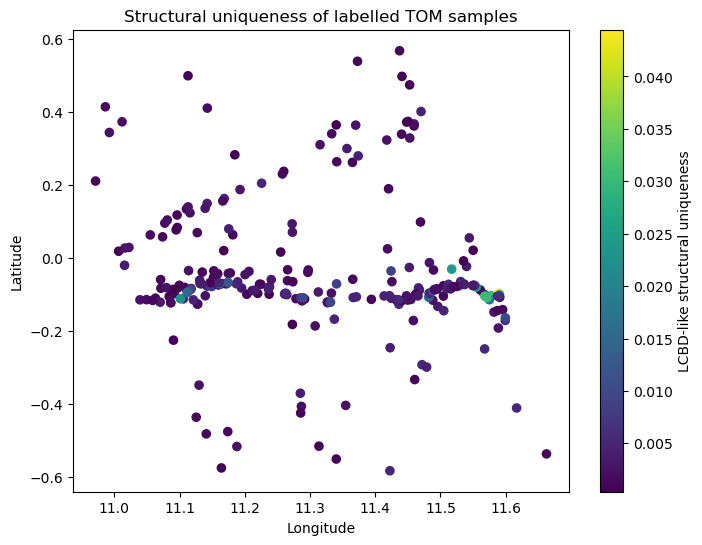

In [23]:
X_struct=rf_clean[features_9].to_numpy(dtype=float)
scaler_lcbd=StandardScaler()
Xz=scaler_lcbd.fit_transform(X_struct)
centroid=Xz.mean(axis=0)

ss=np.sum((Xz-centroid)**2,axis=1)
lcbd_structural=ss/ss.sum()

rf_clean=rf_clean.copy()
rf_clean["structural_lcbd"]=lcbd_structural

print(rf_clean.groupby("class")["structural_lcbd"].median().round(6))

plt.figure(figsize=(8,6))
plt.scatter(
    rf_clean["lon"],rf_clean["lat"],
    c=rf_clean["structural_lcbd"],s=35
)
plt.colorbar(label="LCBD-like structural uniqueness")
plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.title("Structural uniqueness of labelled TOM samples")
plt.show()


## STEP 22 — Spatial cross-validation diagnostic


In [24]:
from sklearn.cluster import KMeans as SpatialKMeans
from sklearn.model_selection import GroupKFold

coords=rf_clean[["lon","lat"]].to_numpy()

spatial_clusterer=SpatialKMeans(
    n_clusters=5,n_init=30,random_state=42
)
spatial_groups=spatial_clusterer.fit_predict(coords)
rf_clean["spatial_fold"]=spatial_groups

print(pd.crosstab(rf_clean["spatial_fold"],rf_clean["class"]))

group_cv=GroupKFold(n_splits=5)

rf_spatial=RandomForestClassifier(
    n_estimators=600,max_features="sqrt",min_samples_leaf=2,
    class_weight="balanced",random_state=42,n_jobs=-1
)

spatial_scores=cross_validate(
    rf_spatial,
    rf_clean[features_9],
    rf_clean["class"],
    groups=rf_clean["spatial_fold"],
    cv=group_cv,
    scoring=scoring,
    n_jobs=-1
)

print("Spatial CV balanced accuracy:",
      spatial_scores["test_balanced_accuracy"].mean(),"+/-",
      spatial_scores["test_balanced_accuracy"].std())
print("Spatial CV macro F1:",
      spatial_scores["test_macro_f1"].mean(),"+/-",
      spatial_scores["test_macro_f1"].std())


class         Other / non-reference  Savanna  Tree cover areas (Dense)  \
spatial_fold                                                             
0                                 0        0                        16   
1                                36       33                        11   
2                                 0        0                        13   
3                                36       17                         5   
4                                 0        0                        14   

class         Tree cover areas (open)  
spatial_fold                           
0                                   0  
1                                   2  
2                                  18  
3                                  35  
4                                   9  
Spatial CV balanced accuracy: 0.2840234112292936 +/- 0.11868673260848785
Spatial CV macro F1: 0.19601456232805683 +/- 0.10138808063633381


/opt/conda/lib/python3.12/site-packages/sklearn/metrics/_classification.py:2524: UserWarning: y_pred contains classes not in y_true
  warnings.warn("y_pred contains classes not in y_true")
/opt/conda/lib/python3.12/site-packages/sklearn/metrics/_classification.py:2524: UserWarning: y_pred contains classes not in y_true
  warnings.warn("y_pred contains classes not in y_true")
/opt/conda/lib/python3.12/site-packages/sklearn/metrics/_classification.py:2524: UserWarning: y_pred contains classes not in y_true
  warnings.warn("y_pred contains classes not in y_true")


## STEP 23 — Optional full-scene 4-class diagnostic map


In [25]:
RUN_FULL_SCENE_3CLASS=True

if RUN_FULL_SCENE_3CLASS:
    rf_map_3=RandomForestClassifier(
        n_estimators=800,max_features="sqrt",min_samples_leaf=2,
        class_weight="balanced",random_state=42,n_jobs=-1
    )
    rf_map_3.fit(rf_clean[features_9],rf_clean["class"])

    n_lat=cube.sizes["lat"]; n_lon=cube.sizes["lon"]
    classification_map_3class=np.full((n_lat,n_lon),np.nan,dtype=np.float32)
    confidence_map_3class=np.full((n_lat,n_lon),np.nan,dtype=np.float32)

    chunk_size=128
    total=int(np.ceil(n_lat/chunk_size))*int(np.ceil(n_lon/chunk_size))
    counter=0

    for la0 in range(0,n_lat,chunk_size):
        la1=min(la0+chunk_size,n_lat)
        for lo0 in range(0,n_lon,chunk_size):
            lo1=min(lo0+chunk_size,n_lon)
            counter+=1
            print(f"\rChunk {counter}/{total}",end="")

            chunk=cube.isel(lat=slice(la0,la1),lon=slice(lo0,lo1))
            cf={p:compute_structural_maps(chunk.sel(pol=p)) for p in ["HH","VV","HV"]}

            Xnp=np.column_stack([
                cf["HH"]["width80"].ravel(),cf["HH"]["entropy"].ravel(),cf["HH"]["asymmetry"].ravel(),
                cf["VV"]["width80"].ravel(),cf["VV"]["entropy"].ravel(),cf["VV"]["asymmetry"].ravel(),
                cf["HV"]["width80"].ravel(),cf["HV"]["entropy"].ravel(),cf["HV"]["asymmetry"].ravel(),
            ])

            valid=np.isfinite(Xnp).all(axis=1)
            if not np.any(valid):
                continue

            Xdf=pd.DataFrame(Xnp[valid],columns=features_9)
            labels=rf_map_3.predict(Xdf)
            probs=rf_map_3.predict_proba(Xdf)

            codes=pd.Categorical(labels,categories=rf_map_3.classes_).codes.astype(float)
            conf=probs.max(axis=1)

            class_flat=np.full(Xnp.shape[0],np.nan)
            conf_flat=np.full(Xnp.shape[0],np.nan)
            class_flat[valid]=codes
            conf_flat[valid]=conf

            shape=(la1-la0,lo1-lo0)
            classification_map_3class[la0:la1,lo0:lo1]=class_flat.reshape(shape)
            confidence_map_3class[la0:la1,lo0:lo1]=conf_flat.reshape(shape)

    print("\nDone.")
    for i,c in enumerate(rf_map_3.classes_):
        print(i,"=",c)


Chunk 416/416
Done.
0 = Other / non-reference
1 = Savanna
2 = Tree cover areas (Dense)
3 = Tree cover areas (open)


## STEP 24 — Recommended hierarchical full-scene map


In [28]:
# ============================================================
# STEP 24 — FINAL FULL-SCENE HIERARCHICAL 4-CLASS MAP
# ============================================================

from sklearn.ensemble import RandomForestClassifier

RUN_FINAL_MAP = True


if RUN_FINAL_MAP:

    OTHER_CLASS = "Other / non-reference"

    # ========================================================
    # LEVEL 0 — OTHER vs VEGETATED
    # ========================================================

    level0_target = np.where(
        rf_clean["class"] == OTHER_CLASS,
        OTHER_CLASS,
        "Vegetated"
    )

    rf_level0 = RandomForestClassifier(
        n_estimators=800,
        max_features="sqrt",
        min_samples_leaf=2,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    )

    rf_level0.fit(
        rf_clean[features_15],
        level0_target
    )


    # ========================================================
    # LEVEL 1 — SAVANNA vs TREE COVER
    # ========================================================

    vegetation_classes = [
        "Savanna",
        "Tree cover areas (open)",
        "Tree cover areas (Dense)"
    ]

    train_veg = (
        rf_clean[
            rf_clean["class"].isin(
                vegetation_classes
            )
        ]
        .copy()
    )

    level1_target = np.where(
        train_veg["class"] == "Savanna",
        "Savanna",
        "Tree cover"
    )

    rf_level1 = RandomForestClassifier(
        n_estimators=800,
        max_features="sqrt",
        min_samples_leaf=2,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    )

    rf_level1.fit(
        train_veg[features_15],
        level1_target
    )


    # ========================================================
    # LEVEL 2 — OPEN vs DENSE
    # ========================================================

    tree_classes = [
        "Tree cover areas (open)",
        "Tree cover areas (Dense)"
    ]

    train_tree = (
        rf_clean[
            rf_clean["class"].isin(
                tree_classes
            )
        ]
        .copy()
    )

    rf_level2 = RandomForestClassifier(
        n_estimators=800,
        max_features="sqrt",
        min_samples_leaf=2,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    )

    rf_level2.fit(
        train_tree[features_15],
        train_tree["class"]
    )


    # ========================================================
    # OUTPUT ARRAYS
    # ========================================================

    n_lat = cube.sizes["lat"]
    n_lon = cube.sizes["lon"]

    final_classification_map = np.full(
        (n_lat, n_lon),
        np.nan,
        dtype=np.float32
    )

    final_confidence_map = np.full(
        (n_lat, n_lon),
        np.nan,
        dtype=np.float32
    )

    vegetation_probability_map = np.full(
        (n_lat, n_lon),
        np.nan,
        dtype=np.float32
    )

    dense_probability_map = np.full(
        (n_lat, n_lon),
        np.nan,
        dtype=np.float32
    )


    # --------------------------------------------------------
    # Final class codes
    # --------------------------------------------------------

    class_codes = {
        "Other / non-reference": 0,
        "Savanna": 1,
        "Tree cover areas (open)": 2,
        "Tree cover areas (Dense)": 3
    }


    # ========================================================
    # CLASS INDICES FOR PROBABILITY ARRAYS
    # ========================================================

    idx_vegetated = list(
        rf_level0.classes_
    ).index("Vegetated")

    idx_other = list(
        rf_level0.classes_
    ).index(OTHER_CLASS)

    idx_savanna = list(
        rf_level1.classes_
    ).index("Savanna")

    idx_tree = list(
        rf_level1.classes_
    ).index("Tree cover")

    idx_dense = list(
        rf_level2.classes_
    ).index("Tree cover areas (Dense)")


    # ========================================================
    # FULL-SCENE CHUNK PROCESSING
    # ========================================================

    chunk_size = 128

    total_chunks = (
        int(np.ceil(n_lat / chunk_size))
        *
        int(np.ceil(n_lon / chunk_size))
    )

    counter = 0


    for la0 in range(
        0,
        n_lat,
        chunk_size
    ):

        la1 = min(
            la0 + chunk_size,
            n_lat
        )

        for lo0 in range(
            0,
            n_lon,
            chunk_size
        ):

            lo1 = min(
                lo0 + chunk_size,
                n_lon
            )

            counter += 1

            print(
                f"\rChunk {counter}/{total_chunks}",
                end=""
            )


            # =================================================
            # TOM CHUNK
            # =================================================

            chunk = cube.isel(
                lat=slice(la0, la1),
                lon=slice(lo0, lo1)
            )


            cf = {
                p: compute_structural_maps(
                    chunk.sel(pol=p)
                )
                for p in [
                    "HH",
                    "VV",
                    "HV"
                ]
            }


            # =================================================
            # BUILD 15-FEATURE MATRIX
            # =================================================

            Xnp = np.column_stack([

                cf["HH"]["width80"].ravel(),
                cf["HH"]["entropy"].ravel(),
                cf["HH"]["asymmetry"].ravel(),
                cf["HH"]["log_power"].ravel(),
                cf["HH"]["log_peak"].ravel(),

                cf["VV"]["width80"].ravel(),
                cf["VV"]["entropy"].ravel(),
                cf["VV"]["asymmetry"].ravel(),
                cf["VV"]["log_power"].ravel(),
                cf["VV"]["log_peak"].ravel(),

                cf["HV"]["width80"].ravel(),
                cf["HV"]["entropy"].ravel(),
                cf["HV"]["asymmetry"].ravel(),
                cf["HV"]["log_power"].ravel(),
                cf["HV"]["log_peak"].ravel()

            ])


            valid = np.isfinite(
                Xnp
            ).all(axis=1)


            if not np.any(valid):
                continue


            Xdf = pd.DataFrame(
                Xnp[valid],
                columns=features_15
            )


            # =================================================
            # LEVEL 0
            # OTHER vs VEGETATED
            # =================================================

            pred0 = rf_level0.predict(
                Xdf
            )

            prob0 = rf_level0.predict_proba(
                Xdf
            )

            p_vegetated = prob0[
                :,
                idx_vegetated
            ]

            p_other = prob0[
                :,
                idx_other
            ]


            # =================================================
            # LEVEL 1
            # SAVANNA vs TREE COVER
            # =================================================

            pred1 = rf_level1.predict(
                Xdf
            )

            prob1 = rf_level1.predict_proba(
                Xdf
            )

            p_savanna = prob1[
                :,
                idx_savanna
            ]

            p_tree = prob1[
                :,
                idx_tree
            ]


            # =================================================
            # LEVEL 2
            # OPEN vs DENSE
            # =================================================

            pred2 = rf_level2.predict(
                Xdf
            )

            prob2 = rf_level2.predict_proba(
                Xdf
            )

            p_dense = prob2[
                :,
                idx_dense
            ]


            # =================================================
            # FINAL CLASSIFICATION
            # =================================================

            final_labels = np.full(
                len(Xdf),
                OTHER_CLASS,
                dtype=object
            )


            # -------------------------
            # Vegetated pixels
            # -------------------------

            veg_mask = (
                pred0 == "Vegetated"
            )


            # -------------------------
            # Savanna
            # -------------------------

            savanna_mask = (
                veg_mask
                &
                (pred1 == "Savanna")
            )

            final_labels[
                savanna_mask
            ] = "Savanna"


            # -------------------------
            # Tree cover
            # -------------------------

            tree_mask = (
                veg_mask
                &
                (pred1 == "Tree cover")
            )

            final_labels[
                tree_mask
            ] = pred2[
                tree_mask
            ]


            # =================================================
            # FINAL CLASS CODES
            # =================================================

            final_codes = np.array(
                [
                    class_codes[label]
                    for label in final_labels
                ],
                dtype=np.float32
            )


            # =================================================
            # HIERARCHICAL CONFIDENCE
            # =================================================

            confidence = np.zeros(
                len(Xdf),
                dtype=float
            )


            # Other
            other_mask = ~veg_mask

            confidence[
                other_mask
            ] = p_other[
                other_mask
            ]


            # Savanna
            confidence[
                savanna_mask
            ] = (
                p_vegetated[
                    savanna_mask
                ]
                *
                p_savanna[
                    savanna_mask
                ]
            )


            # Tree cover
            if np.any(tree_mask):

                tree_subclass_conf = (
                    prob2[
                        tree_mask
                    ].max(
                        axis=1
                    )
                )

                confidence[
                    tree_mask
                ] = (
                    p_vegetated[
                        tree_mask
                    ]
                    *
                    p_tree[
                        tree_mask
                    ]
                    *
                    tree_subclass_conf
                )


            # =================================================
            # WRITE CHUNK TO OUTPUT MAPS
            # =================================================

            n_chunk_pixels = Xnp.shape[0]

            class_flat = np.full(
                n_chunk_pixels,
                np.nan
            )

            conf_flat = np.full(
                n_chunk_pixels,
                np.nan
            )

            veg_flat = np.full(
                n_chunk_pixels,
                np.nan
            )

            dense_flat = np.full(
                n_chunk_pixels,
                np.nan
            )


            class_flat[
                valid
            ] = final_codes

            conf_flat[
                valid
            ] = confidence

            veg_flat[
                valid
            ] = p_vegetated


            dense_values = np.full(
                len(Xdf),
                np.nan
            )

            dense_values[
                tree_mask
            ] = p_dense[
                tree_mask
            ]

            dense_flat[
                valid
            ] = dense_values


            shape = (
                la1 - la0,
                lo1 - lo0
            )


            final_classification_map[
                la0:la1,
                lo0:lo1
            ] = class_flat.reshape(
                shape
            )


            final_confidence_map[
                la0:la1,
                lo0:lo1
            ] = conf_flat.reshape(
                shape
            )


            vegetation_probability_map[
                la0:la1,
                lo0:lo1
            ] = veg_flat.reshape(
                shape
            )


            dense_probability_map[
                la0:la1,
                lo0:lo1
            ] = dense_flat.reshape(
                shape
            )


    print(
        "\n\nFINAL MAP COMPLETED."
    )


    # ========================================================
    # CLASS STATISTICS
    # ========================================================

    print("\nClass legend:")

    for name, code in class_codes.items():
        print(
            code,
            "=",
            name
        )


    valid_final = np.isfinite(
        final_classification_map
    )


    values, counts = np.unique(
        final_classification_map[
            valid_final
        ],
        return_counts=True
    )


    print("\nPixel counts:")

    for value, count in zip(
        values,
        counts
    ):

        percentage = (
            100
            *
            count
            /
            counts.sum()
        )

        print(
            f"{int(value)} = "
            f"{int(count):,} pixels "
            f"({percentage:.2f}%)"
        )

Chunk 416/416

FINAL MAP COMPLETED.

Class legend:
0 = Other / non-reference
1 = Savanna
2 = Tree cover areas (open)
3 = Tree cover areas (Dense)

Pixel counts:
0 = 60,908 pixels (1.54%)
1 = 381,390 pixels (9.64%)
2 = 1,665,044 pixels (42.10%)
3 = 1,847,459 pixels (46.71%)


## STEP 25 — Export GeoTIFFs for QGIS


In [32]:
# ============================================================
# STEP 25 — EXPORT FINAL 4-CLASS GEOTIFF PRODUCTS
# ============================================================

import rasterio
from rasterio.transform import from_origin
from pathlib import Path
import numpy as np


# ------------------------------------------------------------
# Output directory
# ------------------------------------------------------------

output_dir = Path(
    "BIOMASS_EcoArchitect_final"
)

output_dir.mkdir(
    exist_ok=True
)


# ------------------------------------------------------------
# Georeferencing
# ------------------------------------------------------------

lon_vals = cube.lon.values
lat_vals = cube.lat.values


dx = float(
    np.abs(
        np.median(
            np.diff(
                lon_vals
            )
        )
    )
)


dy = float(
    np.abs(
        np.median(
            np.diff(
                lat_vals
            )
        )
    )
)


west = float(
    lon_vals.min()
    -
    dx / 2
)


north = float(
    lat_vals.max()
    +
    dy / 2
)


transform = from_origin(
    west,
    north,
    dx,
    dy
)


# ============================================================
# FLOAT RASTER WRITER
# ============================================================

def write_float_tif(
    array,
    path,
    description
):

    out = np.flipud(
        array
    )

    nodata = -9999.0


    out2 = np.where(
        np.isfinite(out),
        out,
        nodata
    ).astype(
        np.float32
    )


    with rasterio.open(
        path,
        "w",
        driver="GTiff",
        height=out2.shape[0],
        width=out2.shape[1],
        count=1,
        dtype="float32",
        crs="EPSG:4326",
        transform=transform,
        nodata=nodata,
        compress="LZW"
    ) as dst:

        dst.write(
            out2,
            1
        )

        dst.set_band_description(
            1,
            description
        )


# ============================================================
# CLASS RASTER WRITER
# ============================================================

def write_class_tif(
    array,
    path
):

    out = np.flipud(
        array
    )

    nodata = 255


    out2 = np.full(
        out.shape,
        nodata,
        dtype=np.uint8
    )


    valid = np.isfinite(
        out
    )


    out2[
        valid
    ] = (
        out[
            valid
        ]
        .astype(
            np.uint8
        )
    )


    with rasterio.open(
        path,
        "w",
        driver="GTiff",
        height=out2.shape[0],
        width=out2.shape[1],
        count=1,
        dtype="uint8",
        crs="EPSG:4326",
        transform=transform,
        nodata=nodata,
        compress="LZW"
    ) as dst:

        dst.write(
            out2,
            1
        )

        dst.set_band_description(
            1,
            "Final hierarchical BIOMASS TOM classification"
        )

        dst.update_tags(
            CLASS_0="Other / non-reference",
            CLASS_1="Savanna",
            CLASS_2="Tree cover areas (open)",
            CLASS_3="Tree cover areas (Dense)"
        )


# ============================================================
# EXPORT PRODUCTS
# ============================================================

write_class_tif(
    final_classification_map,
    output_dir
    /
    "Final_EcoArchitect_4classes.tif"
)


write_float_tif(
    vegetation_probability_map,
    output_dir
    /
    "Vegetation_probability.tif",
    "Probability of Vegetated class"
)


write_float_tif(
    dense_probability_map,
    output_dir
    /
    "Dense_likelihood_within_treecover.tif",
    "Probability of Dense tree cover conditional on Tree cover"
)


write_float_tif(
    final_confidence_map,
    output_dir
    /
    "Final_classification_confidence.tif",
    "Hierarchical Random Forest classification confidence"
)


# ============================================================
# FINAL REPORT
# ============================================================

print("=" * 80)
print("FINAL GEOTIFF EXPORT COMPLETE")
print("=" * 80)

print(
    "\nOutput folder:"
)

print(
    output_dir.resolve()
)


print(
    "\nFiles:"
)

for p in sorted(
    output_dir.glob(
        "*.tif"
    )
):

    print(
        "-",
        p.name
    )

FINAL GEOTIFF EXPORT COMPLETE

Output folder:
/home/jovyan/BIOMASS_EcoArchitect_final

Files:
- Dense_likelihood_within_treecover.tif
- Final_EcoArchitect_4classes.tif
- Final_classification_confidence.tif
- Vegetation_probability.tif


# Interpretation checklist

- **Foundation:** TOM profiles, horizontal slices, structural clustering and heterogeneity.
- **3-class RF:** direct test against the mapped classes.
- **Savanna vs Tree cover:** preferred if this is substantially more accurate.
- **Open vs Dense:** treat as a continuum if classification remains weak.
- **Rao's Q:** local multivariate structural diversity.
- **LCBD-like score:** structural uniqueness relative to the sampled landscape.
- **Spatial CV:** more conservative estimate of geographic generalization than random CV.
- **GeoTIFFs:** use in QGIS for visual comparison with the reference map.

Do not describe Rao's Q or LCBD-like outputs as taxonomic biodiversity. They are tomography-derived habitat-structure proxies.
